# WESAD Dataset Exploration for the Stress-Pattern Model



## Dataset used

**WESAD — Wearable Stress and Affect Detection** is the source dataset. Each participant folder has a synchronized recording dictionary. This project uses:

- `signal['wrist']['BVP']` — blood-volume-pulse waveform, sampled at 64 Hz.
- `label` — protocol labels sampled at 700 Hz.
- Only label `1` (baseline) and label `2` (stress) become the binary training target.

The original WESAD folders are already present at `data/wesad/WESAD`; the derived cached windows are at `data/wesad/prepared_v2*.npz` and `runs/stress_wesad/accepted_windows.csv`.

In [1]:
from pathlib import Path
import json
import math
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, detrend, resample_poly, sosfiltfilt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'wesad' / 'WESAD').exists():
    PROJECT_ROOT = Path.home() / 'code' / 'pulse-usb'

WESAD_DIR = PROJECT_ROOT / 'data' / 'wesad' / 'WESAD'
ARTIFACT_ROOT = PROJECT_ROOT / 'artifacts' / 'stress'
artifact_runs = sorted(path for path in ARTIFACT_ROOT.iterdir() if (path / 'accepted_windows.csv').exists())
RUN_DIR = artifact_runs[-1]
BVP_FS, LABEL_FS, TARGET_FS = 64, 700, 30

assert WESAD_DIR.exists(), f'Original WESAD data not found: {WESAD_DIR}'
print('Project:', PROJECT_ROOT)
print('Participants:', ', '.join(p.name for p in sorted(WESAD_DIR.glob('S*')) if p.is_dir()))
print('BVP sample rate:', BVP_FS, 'Hz | protocol-label sample rate:', LABEL_FS, 'Hz')
print('Model audit artifact:', RUN_DIR.relative_to(PROJECT_ROOT))

Project: /home/shinichi/code/pulse-usb
Participants: S10, S11, S13, S14, S15, S16, S17, S2, S3, S4, S5, S6, S7, S8, S9
BVP sample rate: 64 Hz | protocol-label sample rate: 700 Hz
Model audit artifact: artifacts/stress/20261122T152429_753234Z_v2


In [2]:
# Inspect one original participant recording without altering it.
subject_id = 'S2'
subject_path = WESAD_DIR / subject_id / f'{subject_id}.pkl'
with subject_path.open('rb') as handle:
    record = pickle.load(handle, encoding='latin1')

wrist = record['signal']['wrist']
print('Top-level keys:', list(record.keys()))
print('\nWrist channels and shapes:')
for name, values in wrist.items():
    print(f'  {name:5s} {np.asarray(values).shape}')

labels = np.asarray(record['label']).reshape(-1)
label_names = {0: 'undefined / transient', 1: 'baseline', 2: 'stress', 3: 'amusement', 4: 'meditation', 5: 'other', 6: 'other', 7: 'other'}
label_counts = pd.Series(labels).value_counts().sort_index()
label_table = pd.DataFrame({'WESAD label': label_counts.index, 'Meaning': [label_names.get(int(value), 'other') for value in label_counts.index], 'Samples at 700 Hz': label_counts.values, 'Minutes': label_counts.values / LABEL_FS / 60})
display(label_table.round({'Minutes': 2}))

Top-level keys: ['signal', 'label', 'subject']

Wrist channels and shapes:
  ACC   (194528, 3)
  BVP   (389056, 1)
  EDA   (24316, 1)
  TEMP  (24316, 1)


,WESAD label,Meaning,Samples at 700 Hz,Minutes
0,0,undefined / transient,2142701,51.02
1,1,baseline,800800,19.07
2,2,stress,430500,10.25
3,3,amusement,253400,6.03
4,4,meditation,537599,12.80
5,6,other,45500,1.08
6,7,other,44800,1.07


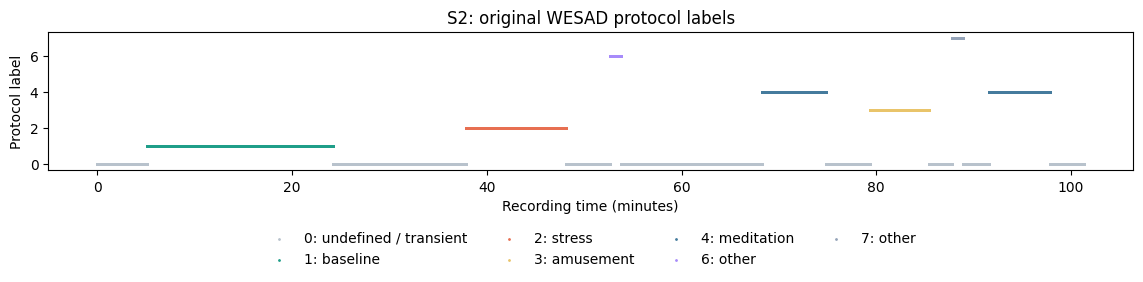

In [3]:
# Protocol timeline for the same participant. Retained baseline/stress segments are visible.
palette = {0: '#b8c2cc', 1: '#1f9e89', 2: '#e76f51', 3: '#e9c46a', 4: '#457b9d', 6: '#a78bfa', 7: '#94a3b8'}
fig, ax = plt.subplots(figsize=(14, 1.8))
for value in np.unique(labels):
    mask = labels == value
    ax.scatter(np.flatnonzero(mask) / LABEL_FS / 60, np.full(mask.sum(), value), s=1, color=palette.get(int(value), '#777777'), label=f'{value}: {label_names.get(int(value), "other")}')
ax.set(xlabel='Recording time (minutes)', ylabel='Protocol label', title=f'{subject_id}: original WESAD protocol labels')
ax.legend(ncol=4, bbox_to_anchor=(0.5, -0.35), loc='upper center', frameon=False)
plt.show()

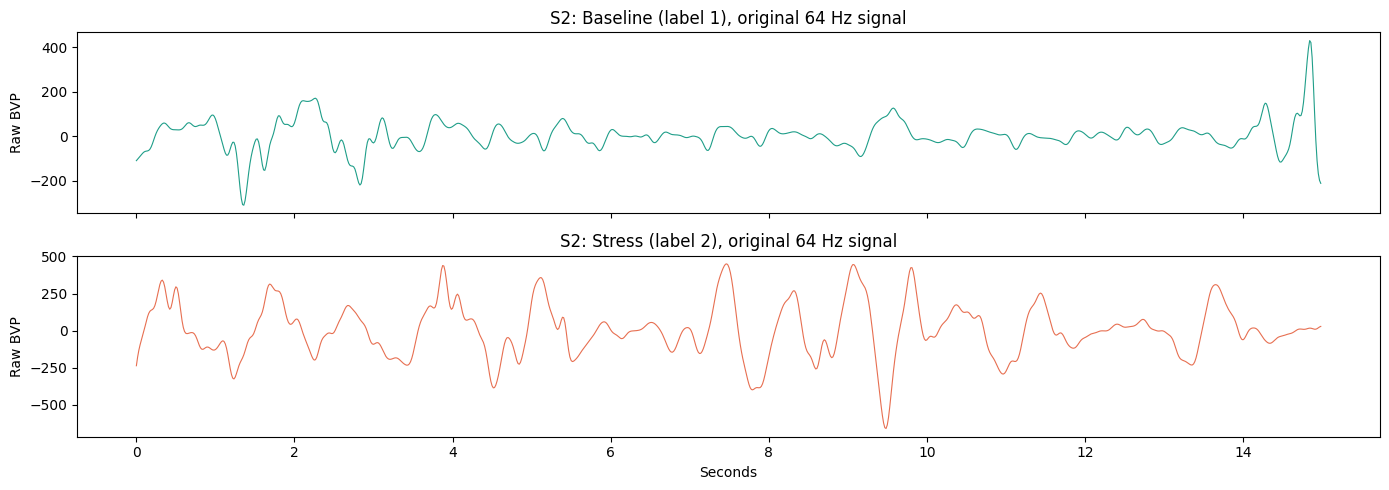

In [4]:
# Compare 15 seconds of raw wrist BVP from a baseline region and a stress region.
raw_bvp = np.asarray(wrist['BVP']).reshape(-1)

def first_stable_region(target_label, minimum_seconds=20):
    run_start = None
    for index, value in enumerate(labels):
        if value == target_label and run_start is None:
            run_start = index
        if run_start is not None and (value != target_label or index == len(labels) - 1):
            run_end = index if value != target_label else index + 1
            if run_end - run_start >= minimum_seconds * LABEL_FS:
                return run_start
            run_start = None
    raise RuntimeError(f'No {minimum_seconds}-second label-{target_label} section found')

fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, value, name, colour in zip(axes, [1, 2], ['Baseline (label 1)', 'Stress (label 2)'], ['#1f9e89', '#e76f51']):
    label_start = first_stable_region(value)
    bvp_start = int(round(label_start * BVP_FS / LABEL_FS))
    count = 15 * BVP_FS
    ax.plot(np.arange(count) / BVP_FS, raw_bvp[bvp_start:bvp_start + count], color=colour, linewidth=0.8)
    ax.set(ylabel='Raw BVP', title=f'{subject_id}: {name}, original 64 Hz signal')
axes[-1].set_xlabel('Seconds')
plt.tight_layout()
plt.show()

## Preprocessing actually used by the model

1. Keep only continuous original-WESAD regions with one protocol label: baseline (`1`) or stress (`2`).
2. Convert label timing from 700 Hz to the matching wrist-BVP timing at 64 Hz.
3. Take a 64-second BVP context (4,096 samples) every 5 seconds. A 2-second guard at each end is discarded after filtering, leaving the centre 60 seconds.
4. Resample from 64 Hz to 30 Hz using polyphase resampling.
5. Remove linear drift, then apply a zero-phase third-order Butterworth band-pass filter from 0.7 to 3.7 Hz (about 42–222 BPM).
6. Keep the centre 60 seconds (1,800 samples); z-score the waveform within that window.
7. Calculate its first difference and z-score that derivative. The model input has two channels: normalized BVP and normalized BVP derivative, shape `(2, 1800)`.
8. PRV values are diagnostic/reporting features only; they are **not** input features to the trained neural network. Subjects are kept separate between evaluation groups to reduce participant leakage.

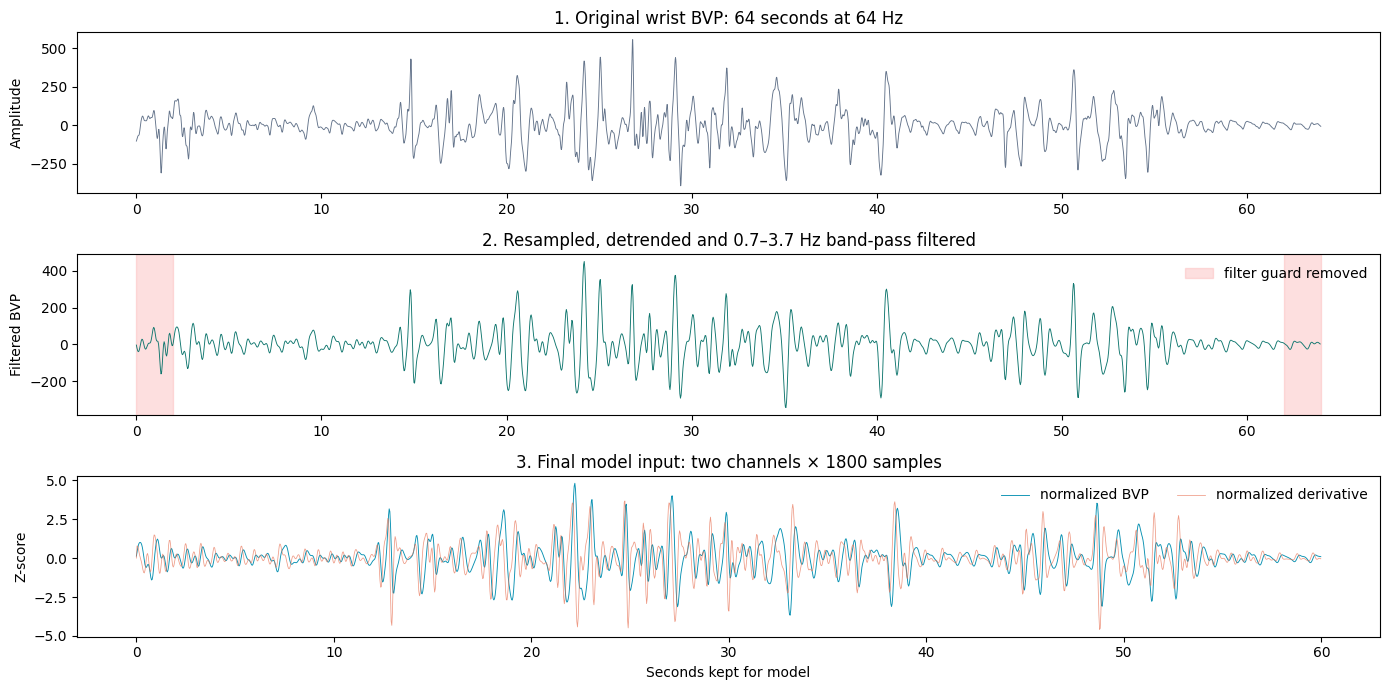

Final waveform shape: (1800,) | final two-channel shape: (2, 1800)


In [5]:
# Visualize the exact raw-to-model transformation for one genuine 64-second context.
context_start_label = first_stable_region(1, minimum_seconds=70)
context_start_bvp = int(np.ceil(context_start_label * BVP_FS / LABEL_FS))
raw_context = raw_bvp[context_start_bvp:context_start_bvp + 64 * BVP_FS]
assert raw_context.size == 64 * BVP_FS

gcd = math.gcd(TARGET_FS, BVP_FS)
resampled = resample_poly(raw_context, TARGET_FS // gcd, BVP_FS // gcd)
sos = butter(3, [0.7, 3.7], btype='bandpass', fs=TARGET_FS, output='sos')
filtered = sosfiltfilt(sos, detrend(resampled, type='linear'))
model_wave = filtered[2 * TARGET_FS:-2 * TARGET_FS]
model_wave = (model_wave - model_wave.mean()) / (model_wave.std() + 1e-8)
model_derivative = np.diff(model_wave, prepend=model_wave[0])
model_derivative = (model_derivative - model_derivative.mean()) / (model_derivative.std() + 1e-8)

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=False)
axes[0].plot(np.arange(raw_context.size) / BVP_FS, raw_context, color='#64748b', linewidth=0.65)
axes[0].set(title='1. Original wrist BVP: 64 seconds at 64 Hz', ylabel='Amplitude')
axes[1].plot(np.arange(filtered.size) / TARGET_FS, filtered, color='#0f766e', linewidth=0.65)
axes[1].axvspan(0, 2, color='#fca5a5', alpha=.35, label='filter guard removed')
axes[1].axvspan(62, 64, color='#fca5a5', alpha=.35)
axes[1].set(title='2. Resampled, detrended and 0.7–3.7 Hz band-pass filtered', ylabel='Filtered BVP')
axes[1].legend(frameon=False, loc='upper right')
axes[2].plot(np.arange(model_wave.size) / TARGET_FS, model_wave, color='#0891b2', linewidth=0.65, label='normalized BVP')
axes[2].plot(np.arange(model_derivative.size) / TARGET_FS, model_derivative, color='#e76f51', linewidth=0.55, alpha=.7, label='normalized derivative')
axes[2].set(title=f'3. Final model input: two channels × {model_wave.size} samples', xlabel='Seconds kept for model', ylabel='Z-score')
axes[2].legend(frameon=False, ncol=2, loc='upper right')
plt.tight_layout()
plt.show()
print('Final waveform shape:', model_wave.shape, '| final two-channel shape:', np.stack([model_wave, model_derivative]).shape)

Accepted windows: 5150
Columns: subject, label, context_start_seconds, window_start_seconds, prv_valid, prv_reason, pulse_count, valid_intervals, rejected_interval_fraction, template_correlation, mean_hr_bpm, rmssd_ms, sdnn_ms, Class


Class,Baseline,Stress,Total
subject,,,
2,216,111,327
3,216,116,332
4,219,115,334
5,227,117,344
6,224,118,342
7,225,116,341
8,221,122,343
9,224,117,341
10,224,133,357


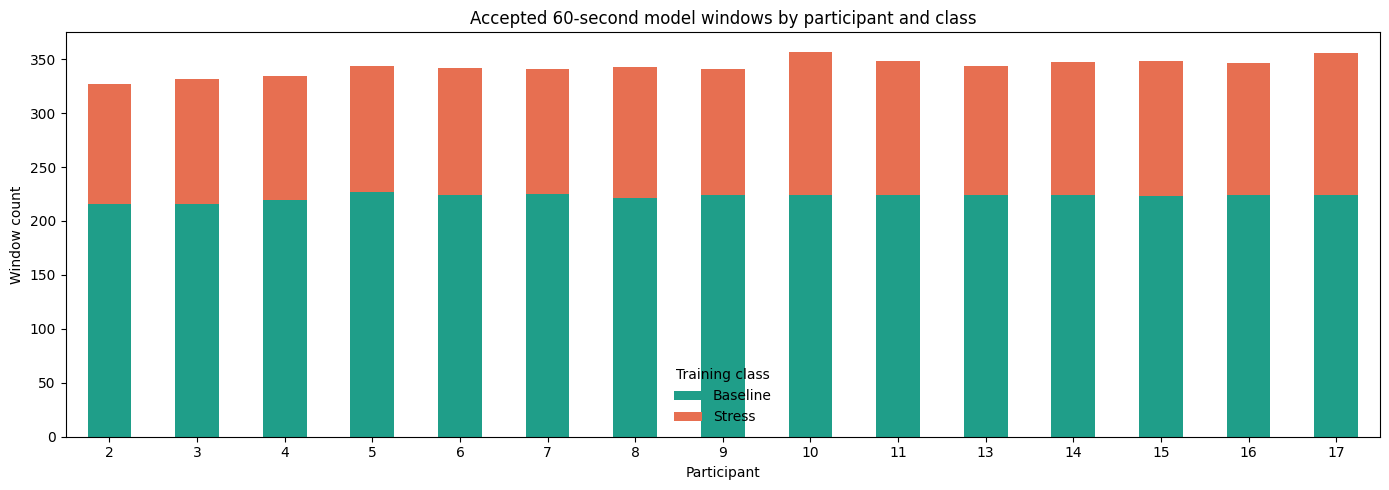

Development subjects (grouped folds): [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14]
Exploratory held-out subjects: [15, 16, 17]


In [6]:
# Model-ready window EDA. This CSV is an audit table for the accepted prepared windows.
accepted_path = RUN_DIR / 'accepted_windows.csv'
accepted = pd.read_csv(accepted_path)
accepted['Class'] = accepted['label'].map({0: 'Baseline', 1: 'Stress'})
print('Accepted windows:', len(accepted))
print('Columns:', ', '.join(accepted.columns))

balance = accepted.groupby(['subject', 'Class']).size().unstack(fill_value=0).sort_index()
display(balance.assign(Total=balance.sum(axis=1)))

ax = balance[['Baseline', 'Stress']].plot(kind='bar', stacked=True, figsize=(14, 5), color=['#1f9e89', '#e76f51'])
ax.set(title='Accepted 60-second model windows by participant and class', xlabel='Participant', ylabel='Window count')
ax.legend(title='Training class', frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

dev_subjects = sorted(set(accepted['subject']) - {15, 16, 17})
print('Development subjects (grouped folds):', dev_subjects)
print('Exploratory held-out subjects:', [15, 16, 17])

In [7]:
# Inspect the compact cache metadata and verify the shape passed to the neural-network data loader.
cache_paths = sorted((PROJECT_ROOT / 'data' / 'wesad').glob('prepared_v2*.npz'))
assert cache_paths, 'No prepared_v2 cache was found.'
cache_path = cache_paths[0]
with np.load(cache_path, allow_pickle=False) as cache:
    print('Cache file:', cache_path.name)
    for key in cache.files:
        print(f'  {key}: {cache[key].shape} {cache[key].dtype}')
    if 'metadata_json' in cache.files:
        metadata = json.loads(str(cache['metadata_json'].item()))
        print('\nMetadata records:', len(metadata))
        print('Metadata fields:', ', '.join(metadata[0].keys()))
        display(pd.DataFrame(metadata).head())

Cache file: prepared_v2_5f6f7408a5cd47f1.npz
  waveform: (5150, 2, 1800) float32
  metadata_json: () <U1928423
  rejections_json: () <U2

Metadata records: 5150
Metadata fields: subject, label, context_start_seconds, window_start_seconds, prv_valid, prv_reason, pulse_count, valid_intervals, rejected_interval_fraction, template_correlation, mean_hr_bpm, rmssd_ms, sdnn_ms


,subject,label,context_start_seconds,window_start_seconds,prv_valid,prv_reason,pulse_count,valid_intervals,rejected_interval_fraction,template_correlation,mean_hr_bpm,rmssd_ms,sdnn_ms
0,2,0,306.5625,308.5625,False,More than 15% locally inconsistent intervals; ...,70.0,42.0,0.391304,0.835750,NaN,NaN,NaN
1,2,0,311.5625,313.5625,False,More than 15% locally inconsistent intervals,68.0,41.0,0.388060,0.862428,NaN,NaN,NaN
2,2,0,316.5625,318.5625,False,More than 15% locally inconsistent intervals; ...,67.0,40.0,0.393939,0.877187,NaN,NaN,NaN
3,2,0,321.5625,323.5625,False,More than 15% locally inconsistent intervals,65.0,42.0,0.343750,0.902031,NaN,NaN,NaN
4,2,0,326.5625,328.5625,False,More than 15% locally inconsistent intervals; ...,67.0,43.0,0.348485,0.895964,NaN,NaN,NaN
